# Análise estatística dos depósitos do Cofrinho Invista+

**Disciplina:** Estatística (PI do 4º semestre, DSM, Fatec Franca)

**Pergunta:** como as crianças e famílias usam o cofrinho? Qual é o depósito típico, quanto ele varia, em que dias a chance de guardar dinheiro é maior, o que se relaciona com o valor guardado no dia, quando a meta será atingida e o que dá para afirmar com confiança sobre a média?

**Dados:** cada linha de `depositos.csv` é um depósito registrado pelo cofrinho (ESP32) e gravado pela API no Firestore. O arquivo é gerado pelo botão *Baixar CSV* da tela de Estatísticas do site.

| Coluna | Significado |
| --- | --- |
| `registradoEm` | Data e hora do depósito (UTC) |
| `valorCentavos` | Valor depositado em centavos |
| `forma` | `moeda` ou `cedula` |
| `pesoGramas` | Peso total do cofre medido pela célula de carga após o depósito |
| `origem` | `sensor` (cofrinho real) ou `simulado` (gerado por `scripts/simular-depositos.js`) |

> Nesta versão os dados são **simulados**. Ao coletar os depósitos do piloto com as famílias, substitua o CSV e execute o notebook de novo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True, 'grid.alpha': 0.3})
AZUL, VERDE, LARANJA = '#004a9f', '#28a745', '#e67e22'
META_REAIS = 150.00
DIAS_ATE_A_META = 60


def num(valor, casas=2):
    return f'{valor:,.{casas}f}'.replace(',', ' ').replace('.', ',').replace(' ', '.')


def brl(valor):
    return f'R$ {num(valor, 2)}'


dados = pd.read_csv('depositos.csv')
dados['registradoEm'] = pd.to_datetime(dados['registradoEm'], utc=True).dt.tz_convert('America/Sao_Paulo')
dados['valor'] = dados['valorCentavos'] / 100
dados['dia'] = dados['registradoEm'].dt.date
dados['diaSemana'] = dados['registradoEm'].dt.dayofweek
dados['fimDeSemana'] = dados['diaSemana'] >= 5
dados = dados.sort_values('registradoEm').reset_index(drop=True)
valores = dados['valor']
print(f'{len(dados)} depósitos de {dados.dia.min()} a {dados.dia.max()}')
print(dados['origem'].value_counts().to_string())
dados.head()

67 depósitos de 2026-07-29 a 2026-09-25
origem
simulado    67


,registradoEm,valorCentavos,forma,pesoGramas,origem,valor,dia,diaSemana,fimDeSemana
0,2026-07-29 18:45:39-03:00,25,moeda,7.5,simulado,0.25,2026-07-29,2,False
1,2026-07-30 09:12:24-03:00,10,moeda,12.2,simulado,0.10,2026-07-30,3,False
2,2026-07-30 12:05:47-03:00,500,cedula,13.2,simulado,5.00,2026-07-30,3,False
3,2026-07-30 15:56:12-03:00,200,cedula,14.2,simulado,2.00,2026-07-30,3,False
4,2026-08-02 12:27:09-03:00,5,moeda,33.2,simulado,0.05,2026-08-02,6,True


## 1. Distribuição de frequências do valor depositado

In [2]:
tabela = valores.value_counts().sort_index().to_frame('frequência')
tabela['relativa (%)'] = (tabela['frequência'] / len(valores) * 100).round(2)
tabela['acumulada'] = tabela['frequência'].cumsum()
tabela['relativa acumulada (%)'] = tabela['relativa (%)'].cumsum().round(2)
tabela.index = [f'{brl(v)}'.replace('.', ',') for v in tabela.index]
tabela

,frequência,relativa (%),acumulada,relativa acumulada (%)
"R$ 0,05",9,13.43,9,13.43
"R$ 0,10",12,17.91,21,31.34
"R$ 0,25",13,19.40,34,50.74
"R$ 0,50",8,11.94,42,62.68
"R$ 1,00",15,22.39,57,85.07
"R$ 2,00",4,5.97,61,91.04
"R$ 5,00",5,7.46,66,98.50
"R$ 10,00",1,1.49,67,99.99


## 2. Medidas de tendência central

In [3]:
media = valores.mean()
mediana = valores.median()
modas = valores.mode().tolist()
print(f'Média: {brl(media)}')
print(f'Mediana: {brl(mediana)}')
print(f'Moda: {", ".join(f"{brl(m)}" for m in modas)} ({"unimodal" if len(modas) == 1 else "multimodal"})')

Média: R$ 1,00
Mediana: R$ 0,25
Moda: R$ 1,00 (unimodal)


## 3. Medidas de dispersão e separatrizes

In [4]:
dp_pop = valores.std(ddof=0)
dp_amostral = valores.std(ddof=1)
q1, q2, q3 = valores.quantile([0.25, 0.5, 0.75])
p10, p90 = valores.quantile([0.10, 0.90])
print(f'Amplitude: {brl(valores.max() - valores.min())} (de {brl(valores.min())} a {brl(valores.max())})')
print(f'Variância populacional: {num(valores.var(ddof=0), 4)}')
print(f'Desvio padrão populacional: {brl(dp_pop)} e amostral: {brl(dp_amostral)}')
print(f'Coeficiente de variação: {num(dp_pop / media * 100, 1)}%')
print(f'Quartis: Q1 = {brl(q1)}, Q2 = {brl(q2)}, Q3 = {brl(q3)}')
print(f'Percentis: P10 = {brl(p10)}, P90 = {brl(p90)}')

Amplitude: R$ 9,95 (de R$ 0,05 a R$ 10,00)
Variância populacional: 2,8680
Desvio padrão populacional: R$ 1,69 e amostral: R$ 1,71
Coeficiente de variação: 169,6%
Quartis: Q1 = R$ 0,10, Q2 = R$ 0,25, Q3 = R$ 1,00
Percentis: P10 = R$ 0,05, P90 = R$ 2,00


## 4. Assimetria e curtose

Classificação da assimetria: |As| < 0,15 simétrica; de 0,15 a 1 moderada; acima de 1 forte. Curtose percentílica: 0,263 é a referência da curva normal (mesocúrtica); abaixo disso a distribuição é leptocúrtica e acima, platicúrtica.

In [5]:
def classificar(coeficiente):
    intensidade = abs(coeficiente)
    if intensidade < 0.15:
        return 'simétrica'
    forca = 'moderada' if intensidade < 1 else 'forte'
    lado = 'positiva (à direita)' if coeficiente > 0 else 'negativa (à esquerda)'
    return f'assimetria {forca} {lado}'

pearson1 = (media - modas[0]) / dp_pop if len(modas) == 1 else float('nan')
pearson2 = 3 * (media - mediana) / dp_pop
fisher = stats.skew(valores, bias=True)
bowley = (q3 + q1 - 2 * q2) / (q3 - q1)
curtose_percentilica = (q3 - q1) / (2 * (p90 - p10))
excesso = stats.kurtosis(valores, fisher=True, bias=True)
print(f'Pearson 1: {num(pearson1, 3)}')
print(f'Pearson 2: {num(pearson2, 3)} → {classificar(pearson2)}')
print(f'Fisher: {num(fisher, 3)}')
print(f'Bowley: {num(bowley, 3)}')
print(f'Curtose percentílica: {num(curtose_percentilica, 3)} → {"leptocúrtica" if curtose_percentilica < 0.263 else "platicúrtica" if curtose_percentilica > 0.263 else "mesocúrtica"}')
print(f'Excesso de curtose (momentos): {num(excesso, 3)}')

Pearson 1: -0,001
Pearson 2: 1,326 → assimetria forte positiva (à direita)
Fisher: 3,168
Bowley: 0,667
Curtose percentílica: 0,231 → leptocúrtica
Excesso de curtose (momentos): 11,282


## 5. Gráficos da distribuição

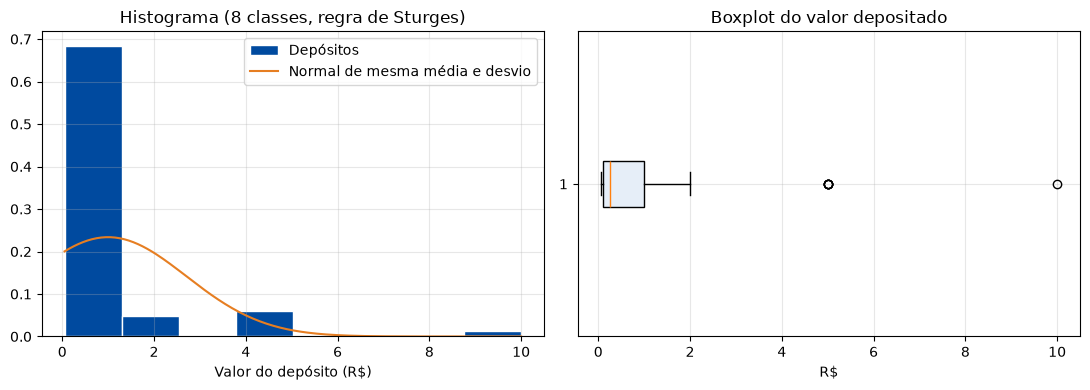

In [6]:
classes = int(np.ceil(1 + np.log2(len(valores))))
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
eixos[0].hist(valores, bins=classes, color=AZUL, edgecolor='white', density=True, label='Depósitos')
x = np.linspace(valores.min(), valores.max(), 200)
eixos[0].plot(x, stats.norm.pdf(x, media, dp_amostral), color=LARANJA, label='Normal de mesma média e desvio')
eixos[0].set_title(f'Histograma ({classes} classes, regra de Sturges)')
eixos[0].set_xlabel('Valor do depósito (R$)')
eixos[0].legend()
eixos[1].boxplot(valores, orientation='horizontal', patch_artist=True, boxprops={'facecolor': '#e6eef8'})
eixos[1].set_title('Boxplot do valor depositado')
eixos[1].set_xlabel('R$')
plt.tight_layout()
plt.show()

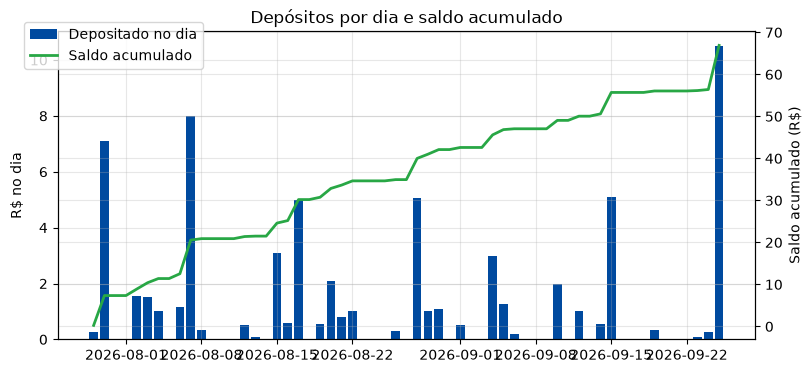

In [7]:
diario = dados.groupby('dia')['valor'].sum()
todos_os_dias = pd.date_range(dados['dia'].min(), dados['dia'].max(), freq='D').date
diario = diario.reindex(todos_os_dias, fill_value=0)
fig, eixo = plt.subplots()
eixo.bar(diario.index, diario.values, color=AZUL, label='Depositado no dia')
eixo2 = eixo.twinx()
eixo2.plot(diario.index, diario.cumsum().values, color=VERDE, linewidth=2, label='Saldo acumulado')
eixo.set_ylabel('R$ no dia')
eixo2.set_ylabel('Saldo acumulado (R$)')
eixo.set_title('Depósitos por dia e saldo acumulado')
fig.legend(loc='upper left', bbox_to_anchor=(0.08, 0.92))
plt.show()

## 6. Probabilidades

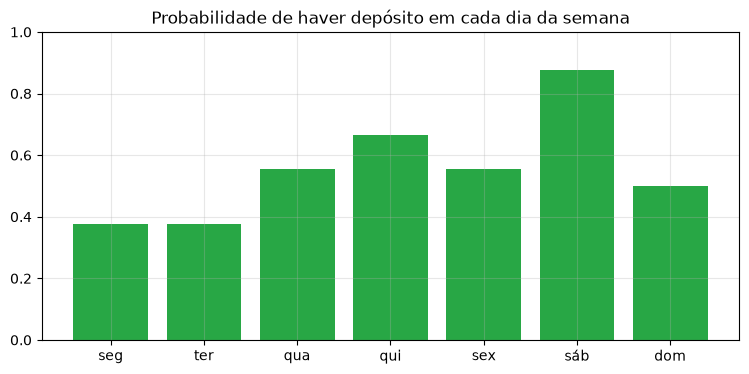

P(depósito na seg) = 0,38
P(depósito na ter) = 0,38
P(depósito na qua) = 0,56
P(depósito na qui) = 0,67
P(depósito na sex) = 0,56
P(depósito na sáb) = 0,88
P(depósito na dom) = 0,50

P(um depósito ser de R$ 1,00 ou mais) = 0,37
Saldo: R$ 66,90; meta: R$ 150,00; faltam R$ 83,10
Depósito diário: média R$ 1,13, desvio R$ 2,15
P(atingir a meta em 60 dias) ≈ 18,26% (aproximação normal pelo Teorema Central do Limite)


In [8]:
nomes = ['seg', 'ter', 'qua', 'qui', 'sex', 'sáb', 'dom']
dias_do_periodo = pd.Series(pd.to_datetime(todos_os_dias)).dt.dayofweek
dias_com_deposito = pd.Series(pd.to_datetime(diario[diario > 0].index)).dt.dayofweek
probabilidade = (dias_com_deposito.value_counts() / dias_do_periodo.value_counts()).reindex(range(7), fill_value=0)
plt.bar(nomes, probabilidade.values, color=VERDE)
plt.ylim(0, 1)
plt.title('Probabilidade de haver depósito em cada dia da semana')
plt.show()
for nome, p in zip(nomes, probabilidade.values):
    print(f'P(depósito na {nome}) = {num(p, 2)}')

p_um_real = (valores >= 1).mean()
print(f'\nP(um depósito ser de R$ 1,00 ou mais) = {num(p_um_real, 2)}')

saldo = valores.sum()
falta = max(META_REAIS - saldo, 0)
mu, sigma = diario.mean(), diario.std(ddof=1)
z = (falta - mu * DIAS_ATE_A_META) / (sigma * np.sqrt(DIAS_ATE_A_META))
p_meta = 1 - stats.norm.cdf(z)
print(f'Saldo: {brl(saldo)}; meta: {brl(META_REAIS)}; faltam {brl(falta)}')
print(f'Depósito diário: média {brl(mu)}, desvio {brl(sigma)}')
print(f'P(atingir a meta em {DIAS_ATE_A_META} dias) ≈ {num(p_meta * 100, 2)}% (aproximação normal pelo Teorema Central do Limite)')

## 7. Regressão linear

**Tendência:** saldo acumulado em função dos dias desde o primeiro depósito.

**Calibração:** saldo acumulado em moedas em função do peso medido pela balança do cofrinho. Se a relação for forte, o peso serve para conferir o valor guardado.

Saldo = 7,55 + 0,97 × dias   (r = 0,983, R² = 0,966)
Pela reta, o saldo chega a R$ 150,00 cerca de 146 dias após o primeiro depósito.
Saldo em moedas = 0,31 + 0,0682 × peso   (R² = 0,991)


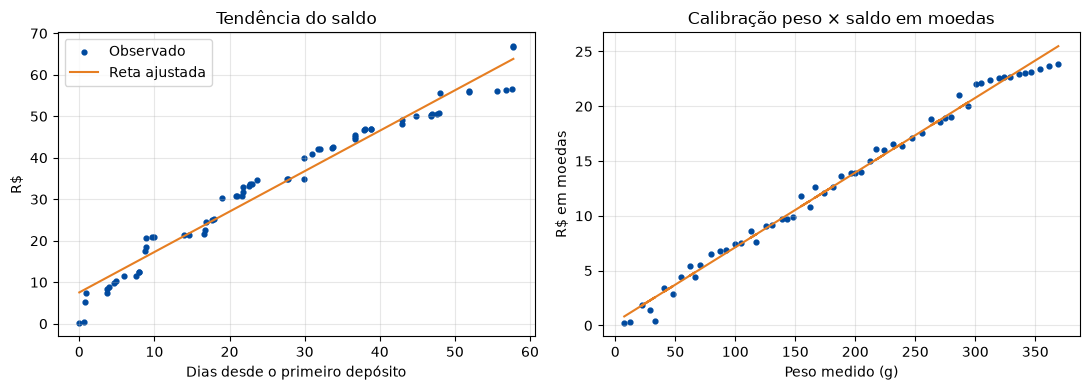

In [9]:
dias_desde_inicio = (dados['registradoEm'] - dados['registradoEm'].iloc[0]).dt.total_seconds() / 86400
saldo_acumulado = valores.cumsum()
tendencia = stats.linregress(dias_desde_inicio, saldo_acumulado)
print(f'Saldo = {num(tendencia.intercept, 2)} + {num(tendencia.slope, 2)} × dias   (r = {num(tendencia.rvalue, 3)}, R² = {num(tendencia.rvalue ** 2, 3)})')
dias_para_meta = (META_REAIS - tendencia.intercept) / tendencia.slope
print(f'Pela reta, o saldo chega a {brl(META_REAIS)} cerca de {num(dias_para_meta, 0)} dias após o primeiro depósito.')

moedas = dados[dados['forma'] == 'moeda'].copy()
moedas['saldoMoedas'] = moedas['valor'].cumsum()
calibracao = stats.linregress(moedas['pesoGramas'], moedas['saldoMoedas'])
print(f'Saldo em moedas = {num(calibracao.intercept, 2)} + {num(calibracao.slope, 4)} × peso   (R² = {num(calibracao.rvalue ** 2, 3)})')

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
eixos[0].scatter(dias_desde_inicio, saldo_acumulado, s=12, color=AZUL, label='Observado')
eixos[0].plot(dias_desde_inicio, tendencia.intercept + tendencia.slope * dias_desde_inicio, color=LARANJA, label='Reta ajustada')
eixos[0].set_title('Tendência do saldo')
eixos[0].set_xlabel('Dias desde o primeiro depósito')
eixos[0].set_ylabel('R$')
eixos[0].legend()
eixos[1].scatter(moedas['pesoGramas'], moedas['saldoMoedas'], s=12, color=AZUL)
eixos[1].plot(moedas['pesoGramas'], calibracao.intercept + calibracao.slope * moedas['pesoGramas'], color=LARANJA)
eixos[1].set_title('Calibração peso × saldo em moedas')
eixos[1].set_xlabel('Peso medido (g)')
eixos[1].set_ylabel('R$ em moedas')
plt.tight_layout()
plt.show()

## 8. Correlação e regressão linear múltipla

A **correlação** mede o grau de relacionamento entre a variável dependente **Y** e as variáveis independentes **X1, X2, ..., Xn**. Valores perto de 1 indicam relação positiva forte (as duas crescem juntas), perto de -1 relação negativa forte (uma cresce e a outra diminui) e perto de 0 ausência de relação linear.

A **regressão linear múltipla** monta a equação Y = b0 + b1·X1 + b2·X2 + b3·X3, usada para **projetar** valores futuros. O p-valor de cada coeficiente mostra se a variável é relevante (p < 5%) ou se poderia sair do modelo.

Cada linha da análise é **um dia com depósito**:

| Variável | Significado |
| --- | --- |
| Y | Total guardado no dia (R$) |
| X1 | Quantidade de depósitos no dia |
| X2 | Fim de semana (1 = sim, 0 = não) |
| X3 | Dia do mês (variável de controle: em princípio não deveria influenciar) |

33 dias com depósito
Matriz de correlação de Pearson:
             total  quantidade  fimDeSemana  diaDoMes
total        1.000       0.465       -0.277     0.158
quantidade   0.465       1.000       -0.108    -0.175
fimDeSemana -0.277      -0.108        1.000    -0.055
diaDoMes     0.158      -0.175       -0.055     1.000
Y x X1 depósitos no dia: r = 0,465 (moderada positiva), p = 0,0064
Y x X2 fim de semana: r = -0,277 (fraca negativa), p = 0,1192
Y x X3 dia do mês: r = 0,158 (desprezível), p = 0,3804


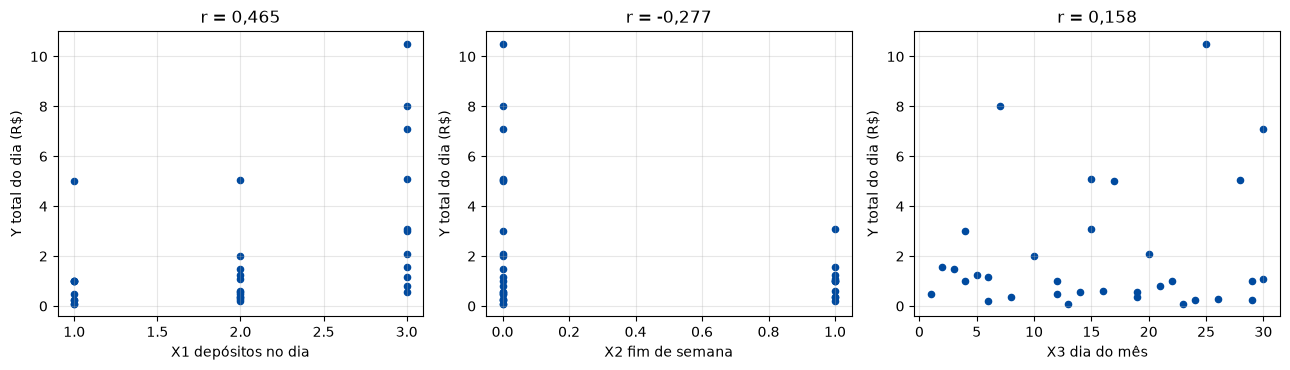

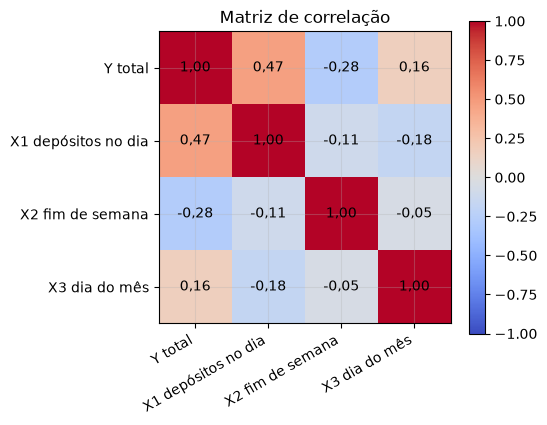

In [10]:
por_dia = dados.groupby('dia').agg(total=('valor', 'sum'), quantidade=('valor', 'size'), fimDeSemana=('fimDeSemana', 'first')).reset_index()
por_dia['fimDeSemana'] = por_dia['fimDeSemana'].astype(int)
por_dia['diaDoMes'] = pd.to_datetime(por_dia['dia']).dt.day
variaveis_x = ['quantidade', 'fimDeSemana', 'diaDoMes']
nomes_x = {'quantidade': 'X1 depósitos no dia', 'fimDeSemana': 'X2 fim de semana', 'diaDoMes': 'X3 dia do mês'}

matriz = por_dia[['total'] + variaveis_x].corr(method='pearson')
print(f'{len(por_dia)} dias com depósito')
print('Matriz de correlação de Pearson:')
print(matriz.round(3).to_string())


def classificar_r(r):
    forca = abs(r)
    if forca < 0.2:
        return 'desprezível'
    nivel = 'muito forte' if forca >= 0.9 else 'forte' if forca >= 0.7 else 'moderada' if forca >= 0.4 else 'fraca'
    return f'{nivel} {"positiva" if r > 0 else "negativa"}'


for x in variaveis_x:
    r, p = stats.pearsonr(por_dia[x], por_dia['total'])
    print(f'Y x {nomes_x[x]}: r = {num(r, 3)} ({classificar_r(r)}), p = {num(p, 4)}')

fig, eixos = plt.subplots(1, 3, figsize=(13, 3.8))
for eixo, x in zip(eixos, variaveis_x):
    eixo.scatter(por_dia[x], por_dia['total'], color=AZUL, s=20)
    eixo.set_xlabel(nomes_x[x])
    eixo.set_ylabel('Y total do dia (R$)')
    eixo.set_title(f'r = {num(por_dia[x].corr(por_dia["total"]), 3)}')
plt.tight_layout()
plt.show()

fig, eixo = plt.subplots(figsize=(5.5, 4.5))
imagem = eixo.imshow(matriz.values, cmap='coolwarm', vmin=-1, vmax=1)
rotulos = ['Y total'] + [nomes_x[x] for x in variaveis_x]
eixo.set_xticks(range(4), rotulos, rotation=30, ha='right')
eixo.set_yticks(range(4), rotulos)
for i in range(4):
    for j in range(4):
        eixo.text(j, i, num(matriz.values[i, j], 2), ha='center', va='center')
eixo.set_title('Matriz de correlação')
fig.colorbar(imagem)
plt.tight_layout()
plt.show()

In [11]:
X = np.column_stack([np.ones(len(por_dia))] + [por_dia[x].to_numpy(dtype=float) for x in variaveis_x])
y = por_dia['total'].to_numpy()
coeficientes, *_ = np.linalg.lstsq(X, y, rcond=None)
residuos = y - X @ coeficientes
graus_liberdade = len(y) - X.shape[1]
variancia_residuo = residuos @ residuos / graus_liberdade
erros_padrao = np.sqrt(np.diag(variancia_residuo * np.linalg.inv(X.T @ X)))
valores_t = coeficientes / erros_padrao
p_valores = 2 * (1 - stats.t.cdf(np.abs(valores_t), graus_liberdade))
r2 = 1 - (residuos @ residuos) / ((y - y.mean()) @ (y - y.mean()))
r2_ajustado = 1 - (1 - r2) * (len(y) - 1) / graus_liberdade

tabela_regressao = pd.DataFrame({
    'coeficiente': coeficientes, 't': valores_t, 'p-valor': p_valores,
    'relevante (5%)': ['', *['sim' if p < 0.05 else 'não' for p in p_valores[1:]]],
}, index=['intercepto'] + [nomes_x[x] for x in variaveis_x])
sinal = lambda v: f'- {num(abs(v), 3)}' if v < 0 else f'+ {num(v, 3)}'
print(f'Y = {num(coeficientes[0], 3)} {sinal(coeficientes[1])}·X1 {sinal(coeficientes[2])}·X2 {sinal(coeficientes[3])}·X3')
print(f'R² = {num(r2, 3)}   R² ajustado = {num(r2_ajustado, 3)}   (gl = {graus_liberdade})')
print(tabela_regressao.round(4).to_string())

cenario = np.array([1, 2, 1, 5])
print(f'Projeção: um sábado ou domingo com 2 depósitos no dia 5 do mês deve somar cerca de {brl(max(cenario @ coeficientes, 0))}.')

Y = -1,687 + 1,521·X1 - 1,129·X2 + 0,064·X3
R² = 0,320   R² ajustado = 0,249   (gl = 29)
                     coeficiente       t  p-valor relevante (5%)
intercepto               -1.6868 -1.1850   0.2457               
X1 depósitos no dia       1.5208  3.0824   0.0045            sim
X2 fim de semana         -1.1290 -1.3725   0.1804            não
X3 dia do mês             0.0643  1.4802   0.1496            não
Projeção: um sábado ou domingo com 2 depósitos no dia 5 do mês deve somar cerca de R$ 0,55.


## 9. Intervalo de confiança

O intervalo de confiança dá uma faixa onde o parâmetro da população deve estar, com um nível de confiança escolhido. Em todos os casos: **[estimativa - ME ; estimativa + ME]**, em que ME é a margem de erro.

| Caso | Margem de erro | Tabela |
| --- | --- | --- |
| 1. Média com desvio padrão **populacional conhecido** (σ) | ME = z<sub>α/2</sub> · σ / √n | Z |
| 2. Média **sem** desvio padrão populacional (usa o amostral s) | ME = t<sub>α/2</sub> · s / √n, com GL = n - 1 | t de Student |
| 3. **Proporção** | ME = z<sub>α/2</sub> · √(p̂ · q̂ / n) | Z |

Para ter uma população e uma amostra de verdade: a **população** são todos os depósitos do arquivo (desde que o cofrinho foi criado), e a **amostra** são os depósitos dos **últimos 30 dias**. No site, a amostra é o período escolhido no filtro.

In [12]:
populacao = valores
amostra = dados.loc[dados['registradoEm'] >= dados['registradoEm'].max() - pd.Timedelta(days=30)]
valores_amostra = amostra['valor']
n_amostra = len(valores_amostra)
x_barra = valores_amostra.mean()
s = valores_amostra.std(ddof=1)
mu = populacao.mean()
sigma = populacao.std(ddof=0)
cedulas = int((amostra['forma'] == 'cedula').sum())
p_chapeu = cedulas / n_amostra

print(f'População: N = {len(populacao)}, μ = {brl(mu)}, σ = {brl(sigma)}')
print(f'Amostra (últimos 30 dias): n = {n_amostra}, x̄ = {brl(x_barra)}, s = {brl(s)}, cédulas = {cedulas} (p̂ = {num(p_chapeu * 100, 1)}%)')

linhas = []
for nivel in [0.90, 0.95, 0.98, 0.99]:
    z = stats.norm.ppf(1 - (1 - nivel) / 2)
    t = stats.t.ppf(1 - (1 - nivel) / 2, n_amostra - 1)
    me_z = z * sigma / np.sqrt(n_amostra)
    me_t = t * s / np.sqrt(n_amostra)
    me_p = z * np.sqrt(p_chapeu * (1 - p_chapeu) / n_amostra)
    linhas.append({
        'nível': f'{nivel:.0%}',
        'z': round(z, 3), '1. média (σ conhecido)': f'{brl(x_barra - me_z)} a {brl(x_barra + me_z)}',
        't': round(t, 3), '2. média (σ desconhecido)': f'{brl(x_barra - me_t)} a {brl(x_barra + me_t)}',
        '3. proporção de cédulas': f'{num(max(p_chapeu - me_p, 0) * 100, 1)}% a {num(min(p_chapeu + me_p, 1) * 100, 1)}%',
    })
tabela_ic = pd.DataFrame(linhas).set_index('nível')
print(tabela_ic.to_string())

z95 = stats.norm.ppf(0.975)
me95 = z95 * sigma / np.sqrt(n_amostra)
print(f'Com 95%: ME = {num(z95, 3)} · {num(sigma, 3)} / √{n_amostra} = {num(me95, 3)}. '
      f'μ = {brl(mu)} {"está" if x_barra - me95 <= mu <= x_barra + me95 else "não está"} dentro do intervalo.')

População: N = 67, μ = R$ 1,00, σ = R$ 1,69
Amostra (últimos 30 dias): n = 31, x̄ = R$ 1,03, s = R$ 2,07, cédulas = 4 (p̂ = 12,9%)
           z 1. média (σ conhecido)      t 2. média (σ desconhecido) 3. proporção de cédulas
nível                                                                                       
90%    1.645      R$ 0,53 a R$ 1,53  1.697         R$ 0,40 a R$ 1,66            3,0% a 22,8%
95%    1.960      R$ 0,44 a R$ 1,63  2.042         R$ 0,27 a R$ 1,79            1,1% a 24,7%
98%    2.326      R$ 0,32 a R$ 1,74  2.457         R$ 0,12 a R$ 1,94            0,0% a 26,9%
99%    2.576      R$ 0,25 a R$ 1,82  2.750         R$ 0,01 a R$ 2,05            0,0% a 28,4%
Com 95%: ME = 1,960 · 1,694 / √31 = 0,596. μ = R$ 1,00 está dentro do intervalo.


## 10. Teste de hipóteses

O teste de hipóteses é parte da inferência estatística: supõe que uma hipótese nula (H0) é verdadeira e verifica se os dados observados são plausíveis sob essa suposição. Segue os 5 passos:

1. Especificar as hipóteses (H0 e H1).
2. Escolher o nível de significância (1%, 5% ou 10%).
3. Coletar os dados.
4. Calcular a estatística do teste.
5. Decidir: se a estatística cair na região de aceitação, não rejeita H0; se cair na região crítica, rejeita H0.

Aqui: **o valor médio dos depósitos no fim de semana é igual ao dos dias úteis?** Teste t de Welch (não supõe variâncias iguais).

In [13]:
alfa = 0.05
fim_de_semana = dados.loc[dados['fimDeSemana'], 'valor']
dias_uteis = dados.loc[~dados['fimDeSemana'], 'valor']
teste = stats.ttest_ind(fim_de_semana, dias_uteis, equal_var=False)
va = fim_de_semana.var(ddof=1) / len(fim_de_semana)
vb = dias_uteis.var(ddof=1) / len(dias_uteis)
gl_welch = (va + vb) ** 2 / (va ** 2 / (len(fim_de_semana) - 1) + vb ** 2 / (len(dias_uteis) - 1))
t_critico_welch = stats.t.ppf(1 - alfa / 2, gl_welch)

print('1. H0: média do fim de semana = média dos dias úteis.  H1: as médias são diferentes.')
print(f'2. Nível de significância: α = {alfa:.0%}.')
print(f'3. Dados: fim de semana n = {len(fim_de_semana)}, média {brl(fim_de_semana.mean())}; dias úteis n = {len(dias_uteis)}, média {brl(dias_uteis.mean())}.')
print(f'4. Estatística: t = {num(teste.statistic, 3)}, gl = {num(gl_welch, 1)}, p-valor = {num(teste.pvalue, 4)}. '
      f'Região crítica: |t| > {num(t_critico_welch, 3)}.')
decisao = 'rejeita H0: as médias são diferentes' if teste.pvalue < alfa else 'não rejeita H0: não há evidência de diferença'
print(f'5. Decisão: p-valor {"<" if teste.pvalue < alfa else ">="} {alfa:.0%}, {decisao}.')

1. H0: média do fim de semana = média dos dias úteis.  H1: as médias são diferentes.
2. Nível de significância: α = 5%.
3. Dados: fim de semana n = 21, média R$ 0,55; dias úteis n = 46, média R$ 1,20.
4. Estatística: t = -2,075, gl = 56,6, p-valor = 0,0426. Região crítica: |t| > 2,003.
5. Decisão: p-valor < 5%, rejeita H0: as médias são diferentes.


## 11. Conferência com a API

A API calcula as mesmas medidas em `lib/estatistica.js` (rota `GET /api/dispositivos/{id}/estatisticas`), e os testes automatizados comparam os resultados com o scipy. Assim, o site, o app e este notebook mostram os mesmos números para os mesmos dados.

## 12. Conclusões

> Texto escrito a partir dos dados simulados deste arquivo. Depois do piloto com as famílias, troque o `depositos.csv` pelos dados reais, execute o notebook de novo e atualize as conclusões.

1. **O depósito típico é pequeno e varia muito.** A mediana (R$ 0,25) fica bem abaixo da média (R$ 1,00), e o coeficiente de variação passa de 160%. A maior parte dos depósitos são moedas de pouco valor; poucas cédulas puxam a média para cima.

2. **A distribuição é assimétrica à direita e leptocúrtica.** Pearson 2 (1,33), Fisher (3,17) e Bowley (0,67) concordam: há uma cauda longa de valores altos. A curtose percentílica (0,231, abaixo de 0,263) e o excesso de curtose (11,3) mostram muitos depósitos concentrados nos valores baixos e alguns valores extremos (cédulas de R$ 5 e R$ 10). Por isso a mediana representa melhor o depósito típico do que a média. O Pearson 1 fica perto de zero porque a moda (R$ 1,00) coincide com a média, o que o torna pouco útil para estes dados.

3. **O dia da semana importa.** A chance de haver depósito é maior no sábado (0,88) e menor na segunda e na terça (0,38). O fim de semana, época de mesada e troco, é o momento em que a criança mais lembra do cofrinho.

4. **No fim de semana os depósitos são mais frequentes, porém menores.** O teste t de Welch (t = -2,08; p = 0,043) rejeita a hipótese de médias iguais a 5%: a média no fim de semana é R$ 0,55, contra R$ 1,20 nos dias úteis.

5. **Tendência e meta.** A reta de regressão explica 96,6% da variação do saldo (R² = 0,966), com crescimento de cerca de R$ 0,97 por dia. Nesse ritmo, a meta de R$ 150 seria atingida cerca de 146 dias após o primeiro depósito, e a chance de chegar lá nos próximos 60 dias é de apenas 18%. No app, isso vira uma orientação educativa: guardar um pouco mais por semana aproxima a meta.

6. **O sensor de peso é confiável para conferir o valor.** O peso medido explica 99,1% da variação do saldo em moedas (R² = 0,991), com cerca de R$ 0,07 por grama. A balança serve para conferir o valor guardado e detectar leituras erradas.

7. **O que se relaciona com o valor guardado no dia.** A quantidade de depósitos no dia tem correlação moderada positiva com o total do dia (r = 0,47; p = 0,006). O fim de semana tem correlação fraca negativa (r = -0,28) e o dia do mês é desprezível (r = 0,16).

8. **Regressão múltipla.** A equação Y = -1,69 + 1,52·X1 - 1,13·X2 + 0,06·X3 explica 25% da variação do total diário (R² ajustado = 0,249). Só a quantidade de depósitos é relevante a 5% (p = 0,0045): cada depósito a mais no dia soma cerca de R$ 1,52. Fim de semana e dia do mês têm p-valor acima de 5% e poderiam sair do modelo, como a variável irrelevante do exemplo da aula. Na prática, o que faz o cofrinho crescer é o hábito de depositar mais vezes.

9. **Intervalos de confiança.** Tomando a amostra dos últimos 30 dias (n = 31, x̄ = R$ 1,03): com desvio populacional conhecido (σ = R$ 1,69, tabela Z), a média de um depósito está entre R$ 0,44 e R$ 1,63 com 95% de confiança, e a média real da população (μ = R$ 1,00) está dentro do intervalo. Sem o desvio populacional (t de Student, GL = 30), o intervalo é mais largo: R$ 0,27 a R$ 1,79. A proporção de depósitos em cédula é de 12,9%, entre 1,1% e 24,7% com 95% de confiança. Quanto maior o nível de confiança, maior o z ou o t e mais largo o intervalo.

10. **Teste de hipóteses em 5 passos.** Com α = 5%, o teste t de Welch dá t = -2,08 e p-valor = 0,043, dentro da região crítica (|t| > 2,003). Por isso rejeitamos H0: o depósito médio no fim de semana (R$ 0,55) é diferente do dos dias úteis (R$ 1,20).
